In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# International population density dataset
country_data = {
    "country": [
        "Ghana",
        "Uganda",
        "United Kingdom",
        "Romania",
        "Guinea",
        "Laos"
    ],
    "area_km2": [
        238500,
        241600,
        243600,
        238400,
        245900,
        236800
    ],
    "population_density": [
        142.9,
        229.0,
        276.8,
        83.1,
        55.8,
        32.3
    ]
}

country_df = pd.DataFrame(country_data)

# Sort countries by population density
country_df = country_df.sort_values(
    by="population_density",
    ascending=False
).reset_index(drop=True)

country_df.insert(
    0,
    "rank",
    range(1, len(country_df) + 1)
)

display(country_df)

,rank,country,area_km2,population_density
0,1,United Kingdom,243600,276.8
1,2,Uganda,241600,229.0
2,3,Ghana,238500,142.9
3,4,Romania,238400,83.1
4,5,Guinea,245900,55.8
5,6,Laos,236800,32.3


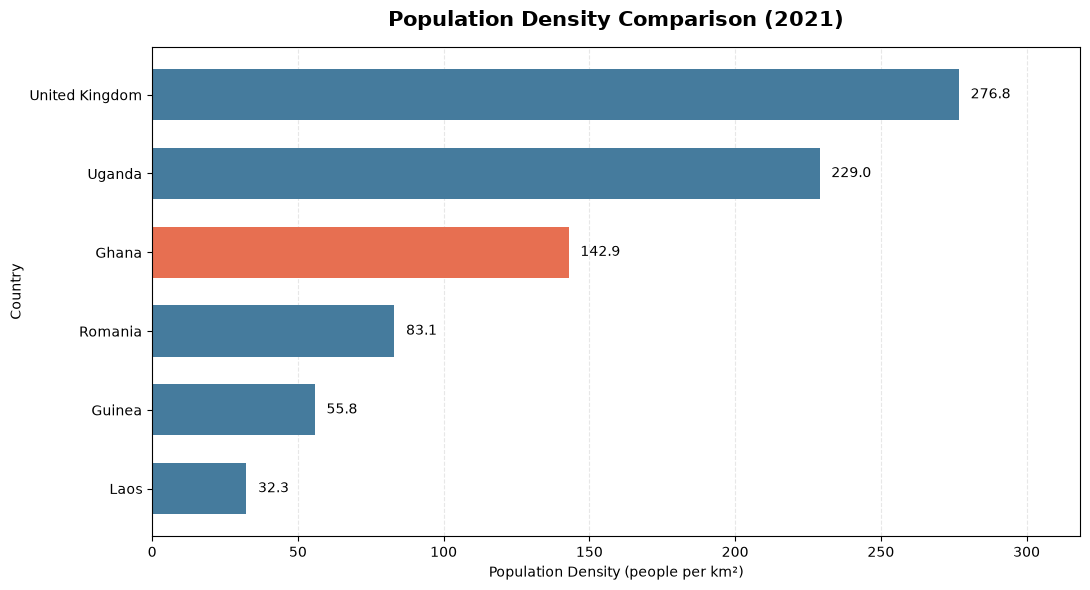

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))

# Assign colours, highlighting Ghana
bar_colors = [
    "#E76F51" if country == "Ghana" else "#457B9D"
    for country in country_df["country"]
]

bars = ax.barh(
    country_df["country"],
    country_df["population_density"],
    color=bar_colors,
    height=0.65
)

# Add population density labels
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 4,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Population Density Comparison (2021)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Population Density (people per km²)")
ax.set_ylabel("Country")

ax.invert_yaxis()
ax.set_xlim(0, country_df["population_density"].max() * 1.15)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

save_file_path = output_dir / "population_density_comparison.png"

fig.savefig(
    save_file_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.tight_layout()
plt.show()

In [3]:
# Extract Ghana's population density
ghana_density = country_df.loc[
    country_df["country"] == "Ghana",
    "population_density"
].iloc[0]

# Calculate density difference relative to Ghana
country_df["density_difference"] = (
    country_df["population_density"] - ghana_density
).round(2)

# Calculate density relative to Ghana
country_df["density_ratio"] = (
    country_df["population_density"] / ghana_density
).round(2)

display(country_df)

,rank,country,area_km2,population_density,density_difference,density_ratio
0,1,United Kingdom,243600,276.8,133.9,1.94
1,2,Uganda,241600,229.0,86.1,1.60
2,3,Ghana,238500,142.9,0.0,1.00
3,4,Romania,238400,83.1,-59.8,0.58
4,5,Guinea,245900,55.8,-87.1,0.39
5,6,Laos,236800,32.3,-110.6,0.23


In [4]:
country_df["density_difference_pct"] = (
    (
        country_df["population_density"] - ghana_density
    ) / ghana_density * 100
).round(2)

display(country_df)

,rank,country,area_km2,population_density,density_difference,density_ratio,density_difference_pct
0,1,United Kingdom,243600,276.8,133.9,1.94,93.70
1,2,Uganda,241600,229.0,86.1,1.60,60.25
2,3,Ghana,238500,142.9,0.0,1.00,0.00
3,4,Romania,238400,83.1,-59.8,0.58,-41.85
4,5,Guinea,245900,55.8,-87.1,0.39,-60.95
5,6,Laos,236800,32.3,-110.6,0.23,-77.40


In [5]:
# Get Ghana's geographical area
ghana_area = country_df.loc[
    country_df["country"] == "Ghana",
    "area_km2"
].iloc[0]

# Calculate area difference relative to Ghana
country_df["area_difference_pct"] = (
    (country_df["area_km2"] - ghana_area)
    / ghana_area * 100
).round(2)

display(
    country_df[
        [
            "country",
            "area_km2",
            "area_difference_pct",
            "population_density"
        ]
    ]
)

,country,area_km2,area_difference_pct,population_density
0,United Kingdom,243600,2.14,276.8
1,Uganda,241600,1.30,229.0
2,Ghana,238500,0.00,142.9
3,Romania,238400,-0.04,83.1
4,Guinea,245900,3.10,55.8
5,Laos,236800,-0.71,32.3


In [6]:
# Calculate average population density of comparison countries
comparison_countries = country_df[
    country_df["country"] != "Ghana"
]

average_density = comparison_countries[
    "population_density"
].mean()

# Compare Ghana with the average
density_difference = ghana_density - average_density

percentage_difference = (
    density_difference / average_density
) * 100

print(f"Average comparison density: {average_density:.2f} people/km²")
print(f"Ghana population density: {ghana_density:.2f} people/km²")
print(f"Difference: {density_difference:.2f} people/km²")
print(f"Percentage difference: {percentage_difference:.2f}%")

Average comparison density: 135.40 people/km²
Ghana population density: 142.90 people/km²
Difference: 7.50 people/km²
Percentage difference: 5.54%


In [7]:
import requests

# World Bank country codes
country_codes = "GHA;UGA;GBR;ROU;GIN;LAO"

url = (
    f"https://api.worldbank.org/v2/country/{country_codes}/"
    "indicator/EN.POP.DNST"
)

params = {
    "date": "2021",
    "format": "json",
    "per_page": 100
}

response = requests.get(url, params=params)
response.raise_for_status()

world_bank_data = response.json()[1]

world_bank_df = pd.DataFrame([
    {
        "country": item["country"]["value"],
        "population_density": item["value"]
    }
    for item in world_bank_data
])

display(world_bank_df)

,country,population_density
0,United Kingdom,276.848675
1,Ghana,142.918456
2,Guinea,55.797302
3,Lao PDR,32.292868
4,Romania,83.110479
5,Uganda,228.959356


In [8]:
# Standardise the country name to match country_df
world_bank_df["country"] = world_bank_df["country"].replace({
    "Lao PDR": "Laos"
})

# Replace the manually entered density values
country_df = country_df.drop(
    columns=["population_density"]
).merge(
    world_bank_df,
    on="country",
    how="left",
    validate="one_to_one"
)

# Check that every country received a value
print("Missing density values:", country_df["population_density"].isna().sum())

# Display the updated dataset
display(
    country_df[
        ["country", "area_km2", "population_density"]
    ]
)

Missing density values: 0


,country,area_km2,population_density
0,United Kingdom,243600,276.848675
1,Uganda,241600,228.959356
2,Ghana,238500,142.918456
3,Romania,238400,83.110479
4,Guinea,245900,55.797302
5,Laos,236800,32.292868


In [9]:
comparison_countries = country_df[
    country_df["country"] != "Ghana"
]

average_density = comparison_countries[
    "population_density"
].mean()

density_difference = ghana_density - average_density

percentage_difference = (
    density_difference / average_density
) * 100

print(f"Average comparison density: {average_density:.2f} people/km²")
print(f"Ghana population density: {ghana_density:.2f} people/km²")
print(f"Difference: {density_difference:.2f} people/km²")
print(f"Percentage difference: {percentage_difference:.2f}%")

Average comparison density: 135.40 people/km²
Ghana population density: 142.90 people/km²
Difference: 7.50 people/km²
Percentage difference: 5.54%


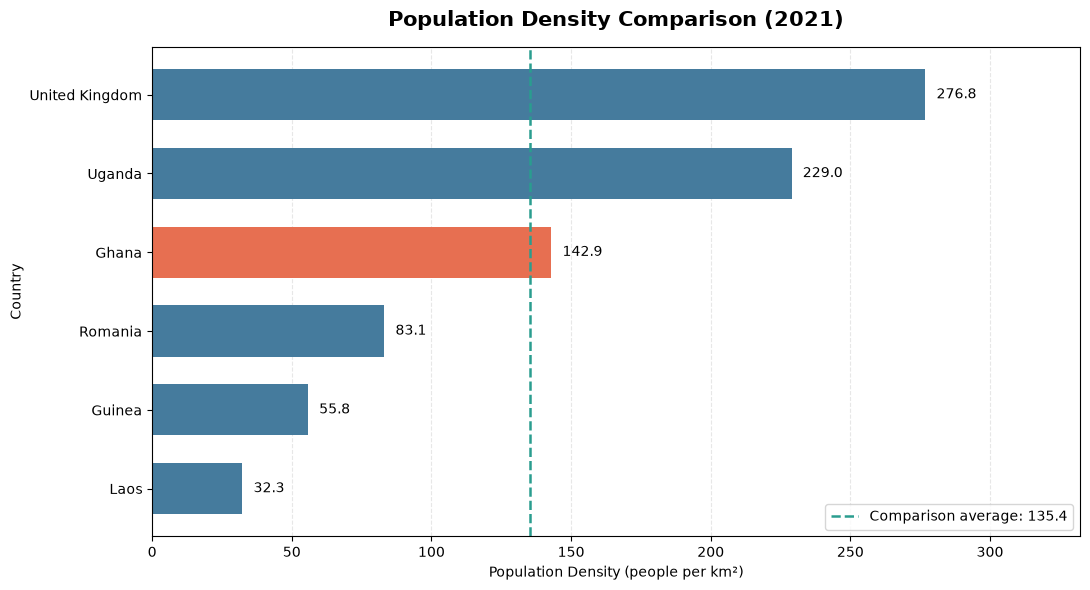

In [23]:
fig, ax = plt.subplots(figsize=(11, 6))

bar_colors = [
    "#E76F51" if country == "Ghana" else "#457B9D"
    for country in country_df["country"]
]

bars = ax.barh(
    country_df["country"],
    country_df["population_density"],
    color=bar_colors,
    height=0.65
)

# Add density values to bars
for bar in bars:
    width = bar.get_width()

    ax.text(
        width + 4,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}",
        va="center",
        fontsize=10
    )

# Add comparison average line
ax.axvline(
    average_density,
    color="#2A9D8F",
    linestyle="--",
    linewidth=1.8,
    label=f"Comparison average: {average_density:.1f}"
)

ax.set_title(
    "Population Density Comparison (2021)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Population Density (people per km²)")
ax.set_ylabel("Country")

ax.invert_yaxis()

ax.set_xlim(
    0,
    country_df["population_density"].max() * 1.2
)

ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

save_file_path = output_dir / "population_density_comparison_average_line.png"

fig.savefig(
    save_file_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


ax.legend()
plt.tight_layout()
plt.show()

In [3]:
# Define output path
PROJECT_ROOT = Path.cwd().parent.parent
DATA_DIR = PROJECT_ROOT / "data"
output_dir = PROJECT_ROOT / "outputs" / "charts"
chart_path = output_dir / "international_population_density_comparison.png"

# Save chart
fig.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight"
)



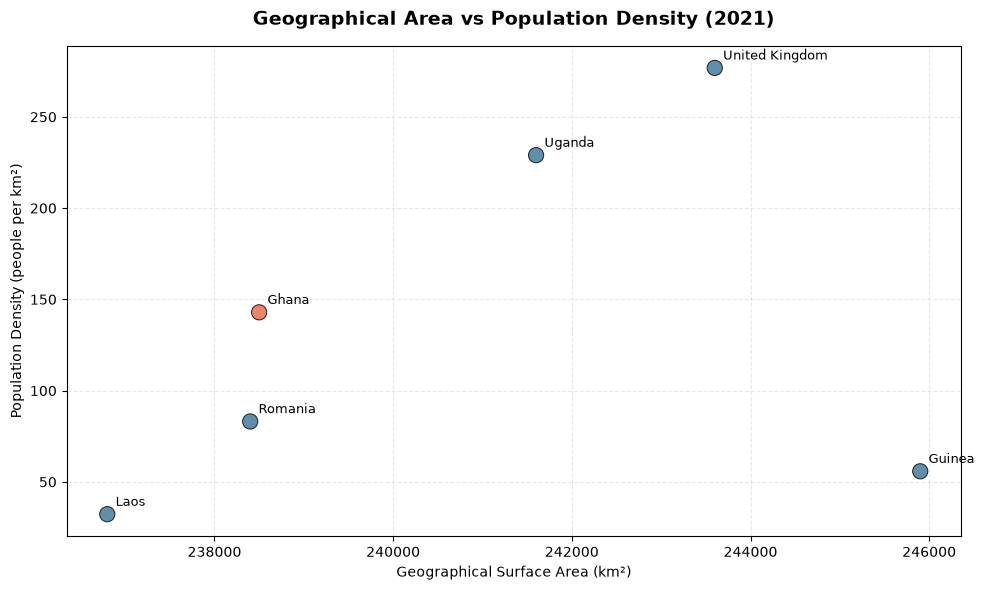

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))

# Highlight Ghana
point_colors = [
    "#E76F51" if country == "Ghana" else "#457B9D"
    for country in country_df["country"]
]

ax.scatter(
    country_df["area_km2"],
    country_df["population_density"],
    c=point_colors,
    s=120,
    alpha=0.85,
    edgecolors="black",
    linewidths=0.7
)

# Add country labels
for _, row in country_df.iterrows():
    ax.annotate(
        row["country"],
        (row["area_km2"], row["population_density"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title(
    "Geographical Area vs Population Density (2021)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Geographical Surface Area (km²)")
ax.set_ylabel("Population Density (people per km²)")

ax.grid(
    linestyle="--",
    alpha=0.3
)

save_file_path = output_dir / "international_area_vs_population_density.png"

fig.savefig(
    save_file_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)


ax.set_axisbelow(True)

plt.tight_layout()
plt.show()